<a href="https://colab.research.google.com/github/trish272000/Thesis/blob/main/notebooks/06_final_results.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 06 — Sensitivity Studies and Final Results
**Thesis:** Uncertainty-Aware Carbon Digital Twin for Sustainable Industrial Systems

| Part | Question |
|---|---|
| 1 | Do the conclusions hold for a looser (2.1%) or stricter (9.3%) emission limit? |
| 2 | How do scheduling savings change with the flexible share (10/20/30%) and shift window (2/4/6 h)? |
| 3 | How much of the cost of uncertainty disappears if the twin knows the **production plan** (which days the plant will work)? |
| 4 | Final thesis tables (LaTeX, ready for Overleaf) |
| 5 | Final thesis figures (numbered copies in one folder) |
| 6 | Key numbers for the abstract and conclusion |

Runs after notebooks 01–05. No GPU is needed.

## Part 0 — Setup

In [1]:
import sys, os, json, shutil
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = "/content/drive/MyDrive/thesis"
else:
    BASE = os.environ.get("THESIS_BASE", os.path.abspath("thesis"))
PROC, FIGS, RES = f"{BASE}/data/processed", f"{BASE}/results/figures", f"{BASE}/results"
TABLES, THESIS_FIGS = f"{RES}/tables", f"{RES}/thesis_figures"
for d in (TABLES, THESIS_FIGS):
    os.makedirs(d, exist_ok=True)
CONFIG = json.load(open(f"{BASE}/config.json"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
from scipy import stats
from scipy.optimize import linprog

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
RNG = np.random.default_rng(42)
SEED = 42
ALPHA = 1 - CONFIG["confidence"]
PREMIUM, PENALTY = CONFIG["green_premium_rs_per_kwh"], CONFIG["penalty_rs_per_t"]

def savefig(name):
    plt.tight_layout()
    plt.savefig(f"{FIGS}/{name}.png", dpi=200, bbox_inches="tight")
    plt.show()

Mounted at /content/drive


In [2]:
# Shared inputs
daily = pd.read_parquet(f"{PROC}/steel_daily.parquet")
caps = pd.read_csv(f"{PROC}/emission_caps.csv").set_index("week_status")
U = {k: pd.read_parquet(f"{PROC}/uq_daily_{k}.parquet") for k in ["A", "B", "C"]}
SAMPLES = np.load(f"{PROC}/uq_samples_C.npy")
ef = json.load(open(f"{PROC}/grid_ef_stats.json"))
a, b = (ef["ef_min"] - ef["ef_mean"]) / ef["ef_std"], (ef["ef_max"] - ef["ef_mean"]) / ef["ef_std"]
K = 300
EF_YEARS = stats.truncnorm.rvs(a, b, loc=ef["ef_mean"], scale=ef["ef_std"], size=K, random_state=RNG) / ef["ef_mean"]
ef_eff = (daily["co2_t"] / (daily["kwh"] / 1000)).median()

C = U["C"].merge(daily[["day", "kwh", "week_status"]], on="day", how="left")
T = (C["role"] == "test").values
TEST = C[T].reset_index(drop=True)
y_t, kwh_t = TEST["co2"].values, TEST["kwh"].values

# Calibrated LSTM-ensemble samples x emission-factor uncertainty (as in notebook 04)
med = np.median(SAMPLES, axis=1); upr = np.quantile(SAMPLES, 1 - ALPHA, axis=1)
cal = (C["role"] == "calib").values
sc = (C["co2"].values[cal] - med[cal]) / np.clip(upr[cal] - med[cal], 1e-6, None)
n = cal.sum()
s = np.quantile(sc, min(1, np.ceil((n + 1) * (1 - ALPHA)) / n), method="higher")
FULL_T = np.clip(med[:, None] + s * (SAMPLES - med[:, None]), 0, None)[T] * RNG.choice(EF_YEARS, size=(T.sum(), SAMPLES.shape[1]))
A_t = U["A"].set_index("day").loc[TEST["day"]]
B_t = U["B"].set_index("day").loc[TEST["day"]]
A_c = U["A"][U["A"].role == "calib"]
worst_err = (A_c["co2"] - A_c["point"]).max()
print("Test days:", len(TEST))

Test days: 61


In [3]:
def share_for(plan, cap):
    return np.clip(1 - cap / np.clip(plan, 1e-6, None), 0, 1)

def optimal_share(Xs, cap, penalty):
    grid = np.linspace(0, 1, 101)
    kwh_fc = Xs.mean(axis=1) / ef_eff * 1000
    out = np.empty(len(Xs))
    for i in range(len(Xs)):
        over = np.clip((1 - grid[:, None]) * Xs[i][None, :] - cap[i], 0, None).mean(axis=1)
        out[i] = grid[np.argmin(grid * kwh_fc[i] * PREMIUM + penalty * over)]
    return out

def play_out(f, cap, y=None, kwh=None, perfect=False):
    y = y_t if y is None else y
    kwh = kwh_t if kwh is None else kwh
    res = []
    for r in EF_YEARS:
        act = y * r
        ff = np.clip(1 - cap / act, 0, 1) if perfect else f
        over_t = np.clip((1 - ff) * act - cap, 0, None)
        green = (ff * kwh * PREMIUM).sum(); pen = PENALTY * over_t.sum()
        res.append([100 * (over_t > cap * 1e-4).mean(), over_t.sum(), green, pen, green + pen])
    return np.mean(res, axis=0)

COLS = ["days over limit (%)", "tonnes over limit", "green power cost (Rs)", "penalty (Rs)", "total cost (Rs)"]

def all_plans(cap):
    plans = {
        "1. No action": np.zeros(len(cap)),
        "2. Single forecast": share_for(A_t["point"].values, cap),
        "3. Fixed worst case": share_for(A_t["point"].values + worst_err, cap),
        "4. Risk-aware 95% (low–high XGBoost)": share_for(B_t["up"].values, cap),
        "5. Risk-aware 95% (LSTM ens. + EF)": share_for(np.quantile(FULL_T, 1 - ALPHA, axis=1), cap),
        "6. Cost-optimal (LSTM ens. + EF)": optimal_share(FULL_T, cap, PENALTY),
    }
    rows = {k: play_out(f, cap) for k, f in plans.items()}
    rows["Perfect knowledge"] = play_out(None, cap, perfect=True)
    return pd.DataFrame(rows, index=COLS).T

## Part 1 — Emission limit: 2.1%, 5.5% and 9.3% below normal
The three values span the CCTS draft range for iron and steel (minimum, median, maximum).

In [4]:
CAP_RES = {}
for col in ["cap_2.1%", "cap_5.5%", "cap_9.3%"]:
    cap = TEST["week_status"].map(caps[col]).values
    CAP_RES[col.replace("cap_", "")] = all_plans(cap)
CAPS = pd.concat(CAP_RES, names=["limit", "plan"])
CAPS.to_csv(f"{RES}/06_cap_sensitivity.csv")
print(CAPS[["days over limit (%)", "tonnes over limit", "total cost (Rs)"]].round(1).to_string())

                                            days over limit (%)  tonnes over limit  total cost (Rs)
limit plan                                                                                         
2.1%  1. No action                                         30.3                8.0          14440.9
      2. Single forecast                                   28.6                6.2          12617.2
      3. Fixed worst case                                   1.8                0.0          15780.2
      4. Risk-aware 95% (low–high XGBoost)                  3.0                0.1          14840.9
      5. Risk-aware 95% (LSTM ens. + EF)                    0.3                0.0          18420.2
      6. Cost-optimal (LSTM ens. + EF)                      8.8                0.7          12781.0
      Perfect knowledge                                     0.0                0.0           4300.0
5.5%  1. No action                                         35.8                9.2          16547.7


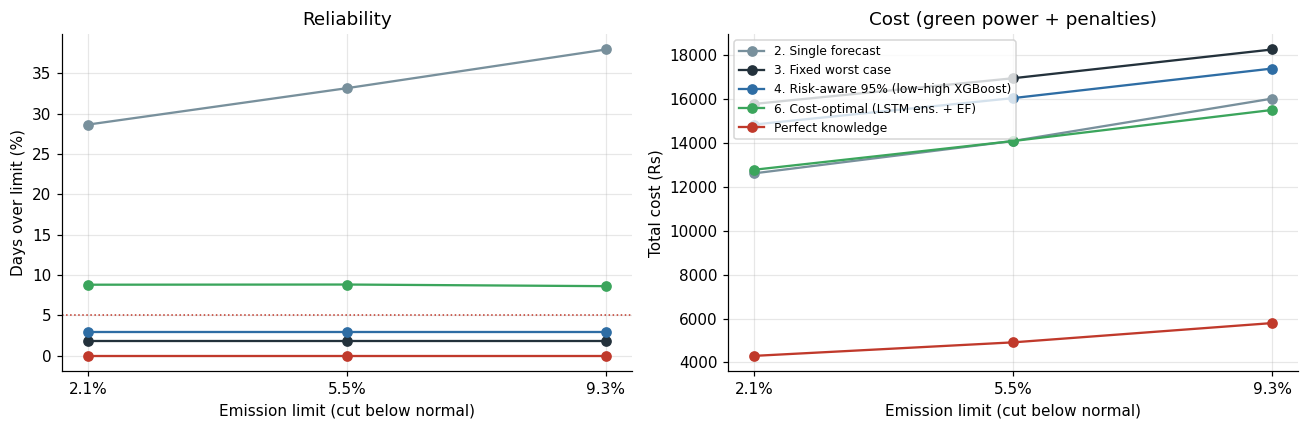

In [5]:
plans_show = ["2. Single forecast", "3. Fixed worst case", "4. Risk-aware 95% (low–high XGBoost)",
              "6. Cost-optimal (LSTM ens. + EF)", "Perfect knowledge"]
pc = {"2": "#78909C", "3": "#23313B", "4": "#2E6DA4", "6": "#3BA55C", "P": "#C0392B"}
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
lims = list(CAP_RES)
for p in plans_show:
    key = p[0] if p[0].isdigit() else "P"
    ax[0].plot(lims, [CAP_RES[l].loc[p, "days over limit (%)"] for l in lims], "o-", color=pc[key], label=p)
    ax[1].plot(lims, [CAP_RES[l].loc[p, "total cost (Rs)"] for l in lims], "o-", color=pc[key], label=p)
ax[0].axhline(100 * ALPHA, color="#C0392B", ls=":", lw=1)
ax[0].set(xlabel="Emission limit (cut below normal)", ylabel="Days over limit (%)", title="Reliability")
ax[1].set(xlabel="Emission limit (cut below normal)", ylabel="Total cost (Rs)", title="Cost (green power + penalties)")
ax[1].legend(fontsize=8, loc="upper left")
savefig("06_cap_sensitivity")

**What to look for.** If the risk-aware plans stay near or below 5% of days over the limit at all three levels, while the
single forecast does not, the main conclusion does not depend on the exact CCTS target chosen.

## Part 2 — Scheduling: flexible share and shift window
The combined objective from notebook 04 (tariff + carbon priced at the green-power cost), run for **every day of 2018**,
so both the summer and winter tariffs are included.

In [6]:
steel = pd.read_parquet(f"{PROC}/steel_prepared.parquet")
steel["ts_hour"] = steel["ts"].dt.floor("h")
GREEN_PER_T = PREMIUM * 1000 / ef_eff

def hourly_with_flex(share):
    st = steel.assign(flex_kwh=np.where(steel["load_type"] == "Maximum_Load", share * steel["kwh"], 0.0))
    h = st.groupby("ts_hour").agg(kwh=("kwh", "sum"), kvah=("kvah", "sum"), flex=("flex_kwh", "sum"),
                                  price=("price_rs_per_kvah", "mean"), ef=("grid_ef_t_per_mwh", "mean"),
                                  season=("season", "first")).reset_index()
    h["day"] = h["ts_hour"].dt.normalize(); h["hour"] = h["ts_hour"].dt.hour
    h["ratio"] = np.where(h["kwh"] > 1, h["kvah"] / h["kwh"].clip(lower=1e-6), 1.0).clip(1, 1.5)
    return h

def schedule_day(g, window, kmax, carbon_price):
    hrs, flex, base = g["hour"].values, g["flex"].values, (g["kwh"] - g["flex"]).values
    unit = g["price"].values * g["ratio"].values + carbon_price * g["ef"].values / 1000
    pairs = [(i, j) for i in range(len(hrs)) if flex[i] > 0 for j in range(len(hrs)) if abs(hrs[j] - hrs[i]) <= window]
    if not pairs:
        return g["kwh"].values
    srcs = sorted({i for i, _ in pairs}); pos = {i: k for k, i in enumerate(srcs)}
    A_eq = np.zeros((len(srcs), len(pairs))); A_ub = np.zeros((len(hrs), len(pairs)))
    for p, (i, j) in enumerate(pairs):
        A_eq[pos[i], p] = 1; A_ub[j, p] = 1
    sol = linprog([unit[j] for _, j in pairs], A_ub=A_ub, b_ub=np.clip(kmax - base, 0, None),
                  A_eq=A_eq, b_eq=[flex[i] for i in srcs], bounds=(0, None), method="highs")
    if not sol.success:
        return g["kwh"].values
    new = base.copy()
    for p, (_, j) in enumerate(pairs):
        new[j] += sol.x[p]
    return new

rows = []
for share in [0.10, 0.20, 0.30]:
    h = hourly_with_flex(share)
    kmax = h["kwh"].max()
    base_cost = (h["kwh"] * h["ratio"] * h["price"]).groupby(h["season"]).sum()
    base_co2 = (h["kwh"] / 1000 * h["ef"]).groupby(h["season"]).sum()
    for window in [2, 4, 6]:
        new = np.empty(len(h))
        for _, g in h.groupby("day"):
            new[g.index] = schedule_day(g, window, kmax, GREEN_PER_T)
        cost = (new * h["ratio"] * h["price"]).groupby(h["season"]).sum()
        co2 = (new / 1000 * h["ef"]).groupby(h["season"]).sum()
        for season in ["summer", "winter"]:
            rows.append({"flexible share": f"{share:.0%}", "window (h)": window, "season": season,
                         "cost change (%)": 100 * (cost[season] / base_cost[season] - 1),
                         "emissions change (%)": 100 * (co2[season] / base_co2[season] - 1),
                         "saving (Rs)": base_cost[season] - cost[season]})
SCHS = pd.DataFrame(rows)
SCHS.to_csv(f"{RES}/06_scheduling_sensitivity.csv", index=False)
print(SCHS.pivot_table(index=["flexible share", "window (h)"], columns="season",
                       values=["cost change (%)", "emissions change (%)"]).round(2).to_string())

                          cost change (%)        emissions change (%)       
season                             summer winter               summer winter
flexible share window (h)                                                   
10%            2                    -0.52  -0.35                 0.20  -0.19
               4                    -0.64  -0.43                 0.02  -0.34
               6                    -0.75  -0.48                 0.12  -0.34
20%            2                    -1.03  -0.70                 0.41  -0.39
               4                    -1.25  -0.87                 0.04  -0.67
               6                    -1.42  -0.96                 0.21  -0.70
30%            2                    -1.53  -1.05                 0.61  -0.58
               4                    -1.84  -1.28                 0.05  -0.99
               6                    -2.01  -1.42                 0.23  -1.13


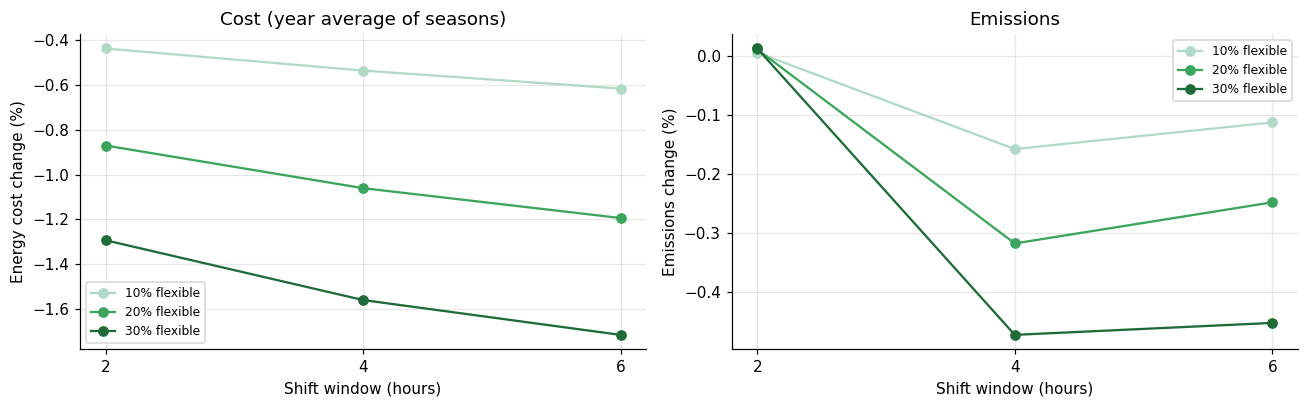

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for share, col in zip(["10%", "20%", "30%"], ["#B0D9C6", "#3BA55C", "#1E6B38"]):
    g = SCHS[SCHS["flexible share"] == share].groupby("window (h)")[["cost change (%)", "emissions change (%)"]].mean()
    ax[0].plot(g.index, g["cost change (%)"], "o-", color=col, label=f"{share} flexible")
    ax[1].plot(g.index, g["emissions change (%)"], "o-", color=col, label=f"{share} flexible")
ax[0].set(xlabel="Shift window (hours)", ylabel="Energy cost change (%)", title="Cost (year average of seasons)")
ax[1].set(xlabel="Shift window (hours)", ylabel="Emissions change (%)", title="Emissions")
for x in ax: x.set_xticks([2, 4, 6]); x.legend(fontsize=8)
savefig("06_scheduling_sensitivity")

## Part 3 — "Production plan known"
Real plants know tomorrow's shift plan. The steel data does not record it, so it is reconstructed: a day is **active**
if its energy use is above 40% of a typical training work day, otherwise **idle**. Two versions of the low–high XGBoost
twin (method B) are trained identically, except that one is told tomorrow's plan.

The difference in total cost, compared with the gap to perfect knowledge, shows **how much of the cost of uncertainty
comes from not knowing the production plan**, i.e. the value of connecting the twin to production planning.

In [8]:
KR_HOLIDAYS_2018 = pd.to_datetime([
    "2018-01-01", "2018-02-15", "2018-02-16", "2018-02-17", "2018-03-01", "2018-05-05", "2018-05-07",
    "2018-05-22", "2018-06-06", "2018-06-13", "2018-08-15", "2018-09-23", "2018-09-24", "2018-09-25",
    "2018-09-26", "2018-10-03", "2018-10-09", "2018-12-25"])
D = daily[["day", "co2_t", "kwh", "cap_t", "split"]].rename(columns={"co2_t": "co2"}).sort_values("day").reset_index(drop=True)
D["dow"] = D["day"].dt.dayofweek; D["month"] = D["day"].dt.month
D["holiday"] = D["day"].isin(KR_HOLIDAYS_2018).astype(int)
D["off_day"] = ((D["dow"] >= 5) | (D["holiday"] == 1)).astype(int)
D["role"] = np.where((D["split"] == "train") & (D["month"] == 8), "valid", D["split"])
typical = D.loc[(D.split == "train") & (D.off_day == 0), "kwh"].median()
D["active"] = (D["kwh"] > 0.4 * typical).astype(int)
for lag, name in [(1, "yday_co2"), (7, "lweek_co2")]:
    D[name] = D["co2"].shift(lag)
D["mean7_co2"] = D["co2"].shift(1).rolling(7).mean()
D["std7_co2"] = D["co2"].shift(1).rolling(7).std()
last, prev = {}, []
for off, c in zip(D["off_day"], D["co2"]):
    prev.append(last.get(off, np.nan)); last[off] = c
D["last_same_type_co2"] = prev
BASE_F = ["dow", "off_day", "holiday", "month", "yday_co2", "lweek_co2", "mean7_co2", "std7_co2", "last_same_type_co2"]
D = D.dropna(subset=BASE_F).reset_index(drop=True)

print("Idle days that were planned work days (weekday, not a holiday):",
      int(((D.active == 0) & (D.off_day == 0)).sum()),
      "| active off-days (weekend/holiday work):", int(((D.active == 1) & (D.off_day == 1)).sum()))

def fit_q(features, q):
    m = xgb.XGBRegressor(objective="reg:quantileerror", quantile_alpha=q, n_estimators=1500, learning_rate=0.03,
                         max_depth=3, min_child_weight=3, subsample=0.8, colsample_bytree=0.8,
                         early_stopping_rounds=100, random_state=SEED)
    tr, va = D.role == "train", D.role == "valid"
    m.fit(D.loc[tr, features], D.loc[tr, "co2"], eval_set=[(D.loc[va, features], D.loc[va, "co2"])], verbose=False)
    return m.predict(D[features])

PLAN_RES = {}
for label, feats in [("Plan unknown", BASE_F), ("Plan known", BASE_F + ["active"])]:
    up = fit_q(feats, 1 - ALPHA); mid = fit_q(feats, 0.5)
    cal_ = (D.role == "calib").values
    sc_ = D["co2"].values[cal_] - up[cal_]
    q = np.quantile(sc_, min(1, np.ceil((cal_.sum() + 1) * (1 - ALPHA)) / cal_.sum()), method="higher")
    PLAN_RES[label] = (mid, up + q)

te = (D.role == "test").values
cap_te, y_te, kwh_te = D.loc[te, "cap_t"].values, D.loc[te, "co2"].values, D.loc[te, "kwh"].values
rows = {}
for label, (mid, upc) in PLAN_RES.items():
    rows[f"Single forecast, {label.lower()}"] = play_out(share_for(mid[te], cap_te), cap_te, y_te, kwh_te)
    rows[f"Risk-aware 95%, {label.lower()}"] = play_out(share_for(upc[te], cap_te), cap_te, y_te, kwh_te)
rows["Perfect knowledge"] = play_out(None, cap_te, y_te, kwh_te, perfect=True)
PLAN = pd.DataFrame(rows, index=COLS).T
PLAN["mean upper bound (t)"] = [np.nan, PLAN_RES["Plan unknown"][1][te].mean(), np.nan,
                               PLAN_RES["Plan known"][1][te].mean(), np.nan]
PLAN.to_csv(f"{RES}/06_production_plan.csv")
print(PLAN.round(2).to_string())

pk = PLAN.loc["Perfect knowledge", "total cost (Rs)"]
u, k = PLAN.loc["Risk-aware 95%, plan unknown", "total cost (Rs)"], PLAN.loc["Risk-aware 95%, plan known", "total cost (Rs)"]
share_removed = (u - k) / (u - pk) if u > pk else np.nan
print(f"\nCost of uncertainty: Rs {u - pk:,.0f} without the plan, Rs {k - pk:,.0f} with it "
      f"-> knowing the production plan removes {share_removed:.0%} of it")

Idle days that were planned work days (weekday, not a holiday): 7 | active off-days (weekend/holiday work): 45
                               days over limit (%)  tonnes over limit  green power cost (Rs)  penalty (Rs)  total cost (Rs)  mean upper bound (t)
Single forecast, plan unknown                32.40               6.86                1611.80      12351.27         13963.07                   NaN
Risk-aware 95%, plan unknown                  2.83               0.14               15529.43        246.46         15775.89                  2.64
Single forecast, plan known                  28.48               5.60                2462.63      10076.88         12539.52                   NaN
Risk-aware 95%, plan known                    3.84               0.26               14355.19        462.03         14817.21                  2.41
Perfect knowledge                             0.00               0.00                4916.16          0.00          4916.16                   NaN

Cost of unce

## Part 4 — Final thesis tables (LaTeX)
Each table is saved as a `.tex` file in `results/tables/`. In Overleaf, upload the folder and use
`\input{tables/T1_forecast_accuracy.tex}`. The preamble needs `\usepackage{booktabs}`, `\usepackage{multirow}` and `\usepackage{graphicx}`.

In [9]:
def to_tex(df, name, caption, label, fmt="{:,.2f}", index=True):
    tex = df.to_latex(index=index, escape=True, float_format=lambda v: fmt.format(v),
                      caption=caption, label=label, position="htbp")
    tex = tex.replace("\\begin{table}[htbp]", "\\begin{table}[htbp]\n\\centering\n\\small")
    tex = tex.replace("\\begin{tabular}", "\\resizebox{\\textwidth}{!}{%\n\\begin{tabular}").replace(
        "\\end{tabular}", "\\end{tabular}}")
    open(f"{TABLES}/{name}.tex", "w").write(tex)
    print(f"saved {name}.tex")

t1 = pd.read_csv(f"{RES}/02_baseline_metrics.csv")
t1 = t1[t1.period == "test"].drop(columns=["period", "daily CO2 MAPE (%)"]).set_index("model")
to_tex(t1, "T1_forecast_accuracy", "Day-ahead single-number forecasts, test period (Nov--Dec 2018).", "tab:forecast")

t2 = pd.read_csv(f"{RES}/03_uncertainty_metrics.csv")
t2 = (t2[t2.period == "test"].drop(columns=["period", "CRPS"]).set_index(["stage", "method"]).sort_index())
to_tex(t2, "T2_uncertainty_calibration", "Raw and calibrated 95\\% ranges for daily emissions, test period.", "tab:uq")

t3 = pd.read_csv(f"{RES}/04_plan_comparison.csv", index_col=0)
to_tex(t3, "T3_green_power_plans", "Green power plans over the test period, averaged over 500 emission-factor years "
       "(penalty Rs 1{,}800/t).", "tab:plans", fmt="{:,.1f}")

t4 = pd.read_csv(f"{RES}/04_scheduling.csv")
t4 = t4[t4.period == "test"].set_index("objective")[["cost change (%)", "emissions change (%)"]]
to_tex(t4, "T4_scheduling", "Flexible-load scheduling, test period: change against the plant as run.", "tab:sched")

t5 = CAPS[["days over limit (%)", "tonnes over limit", "total cost (Rs)"]]
to_tex(t5, "T5_limit_sensitivity", "Sensitivity to the emission limit (CCTS draft range).", "tab:capsens", fmt="{:,.1f}")

t6 = pd.read_csv(f"{RES}/05_gas_turbine_adaptive.csv").set_index(["target", "year", "method"])
to_tex(t6, "T6_gas_turbine", "Gas turbine NOx and CO: fixed vs adaptive calibration of 95\\% ranges, test years.", "tab:gas")

to_tex(PLAN[COLS], "T7_production_plan", "Value of knowing the production plan, test period.", "tab:plan", fmt="{:,.1f}")

saved T1_forecast_accuracy.tex
saved T2_uncertainty_calibration.tex
saved T3_green_power_plans.tex
saved T4_scheduling.tex
saved T5_limit_sensitivity.tex
saved T6_gas_turbine.tex
saved T7_production_plan.tex


## Part 5 — Final thesis figures
Copies of the key figures, renamed in thesis order, in `results/thesis_figures/`.

In [10]:
FIG_MAP = [
    ("Fig01_hourly_grid_intensity", "04_hourly_shape"),
    ("Fig02_price_vs_carbon", "05_price_vs_carbon"),
    ("Fig03_co2_column_check", "02_co2_check"),
    ("Fig04_load_levels", "08_load_levels"),
    ("Fig05_daily_series_and_limit", "08_daily_series"),
    ("Fig06_baseline_forecasts", "02_forecast_vs_actual"),
    ("Fig07_ensemble_uncertainty_split", "03_ensemble_week"),
    ("Fig08_coverage_and_width", "03_coverage_width"),
    ("Fig09_daily_ranges", "03_daily_ranges"),
    ("Fig10_combined_uncertainty", "04_combined_uncertainty"),
    ("Fig11_reliability_vs_cost", "04_reliability_vs_cost"),
    ("Fig12_penalty_sensitivity", "04_penalty_sensitivity"),
    ("Fig13_schedule_example", "04_schedule_example"),
    ("Fig14_limit_sensitivity", "06_cap_sensitivity"),
    ("Fig15_scheduling_sensitivity", "06_scheduling_sensitivity"),
    ("Fig16_gas_turbine_drift", "05_target_drift"),
    ("Fig17_gas_turbine_rolling_coverage", "05_rolling_coverage"),
    ("Fig18_gas_turbine_nox_week", "05_nox_week"),
]
missing = []
for new, old in FIG_MAP:
    src = f"{FIGS}/{old}.png"
    if os.path.exists(src):
        shutil.copy(src, f"{THESIS_FIGS}/{new}.png")
    else:
        missing.append(old)
print(f"Copied {len(FIG_MAP) - len(missing)} figures to {THESIS_FIGS}")
if missing:
    print("Missing (rerun the notebook that makes them):", missing)

Copied 18 figures to /content/drive/MyDrive/thesis/results/thesis_figures


## Part 6 — Key numbers for the abstract and conclusion

In [11]:
P = pd.read_csv(f"{RES}/04_plan_comparison.csv", index_col=0)
U3 = pd.read_csv(f"{RES}/03_uncertainty_metrics.csv")
U3 = U3[(U3.period == "test")]
G5 = pd.read_csv(f"{RES}/05_gas_turbine_adaptive.csv")
S4 = pd.read_csv(f"{RES}/04_scheduling.csv")
s4 = S4[(S4.period == "test") & (S4.objective == "Combined")].iloc[0]
sf, co, ra = P.loc["2. Single forecast"], P.loc["6. Cost-optimal (LSTM ens. + EF)"], P.loc["4. Risk-aware 95% (low–high XGBoost)"]
ens_cal = U3[(U3.stage == "calibrated") & (U3.method == "C. LSTM ensemble")].iloc[0]
ens_raw = U3[(U3.stage == "raw") & (U3.method == "C. LSTM ensemble")].iloc[0]

KEY = {
    "single_forecast_days_over_pct": sf["days over limit (%)"],
    "cost_optimal_days_over_pct": co["days over limit (%)"],
    "cost_optimal_vs_single_cost_change_pct": 100 * (co["total cost (Rs)"] / sf["total cost (Rs)"] - 1),
    "tonnes_over_reduction_pct": 100 * (1 - co["tonnes over limit"] / sf["tonnes over limit"]),
    "risk_aware_95_days_over_pct": ra["days over limit (%)"],
    "risk_aware_95_extra_cost_vs_single_pct": 100 * (ra["total cost (Rs)"] / sf["total cost (Rs)"] - 1),
    "ensemble_coverage_raw_pct": ens_raw["coverage (%)"], "ensemble_coverage_calibrated_pct": ens_cal["coverage (%)"],
    "scheduling_cost_change_pct": s4["cost change (%)"], "scheduling_emissions_change_pct": s4["emissions change (%)"],
    "gas_fixed_coverage_min_pct": G5["fixed: coverage (%)"].min(),
    "gas_adaptive_coverage_range_pct": [G5["adaptive: coverage (%)"].min(), G5["adaptive: coverage (%)"].max()],
    "production_plan_share_of_uncertainty_cost_removed": share_removed,
}
json.dump({k: (float(v) if not isinstance(v, list) else [float(x) for x in v]) for k, v in KEY.items()},
          open(f"{RES}/key_numbers.json", "w"), indent=2)

print(f"* Single-number planning: {KEY['single_forecast_days_over_pct']:.1f}% of days over the limit.")
print(f"* Uncertainty-aware, cost-optimal: {KEY['cost_optimal_days_over_pct']:.1f}% of days over "
      f"({KEY['cost_optimal_vs_single_cost_change_pct']:+.1f}% cost), excess tonnes cut by {KEY['tonnes_over_reduction_pct']:.0f}%.")
print(f"* 95% compliance plan: {KEY['risk_aware_95_days_over_pct']:.1f}% of days over for "
      f"{KEY['risk_aware_95_extra_cost_vs_single_pct']:+.1f}% cost vs single forecast.")
print(f"* Calibration: LSTM-ensemble coverage {KEY['ensemble_coverage_raw_pct']:.0f}% raw -> "
      f"{KEY['ensemble_coverage_calibrated_pct']:.0f}% calibrated (target 95%).")
print(f"* Carbon-aware scheduling: energy cost {KEY['scheduling_cost_change_pct']:+.2f}%, "
      f"emissions {KEY['scheduling_emissions_change_pct']:+.2f}%.")
print(f"* Gas turbine: fixed calibration fell to {KEY['gas_fixed_coverage_min_pct']:.0f}% coverage under drift; "
      f"adaptive kept {KEY['gas_adaptive_coverage_range_pct'][0]:.1f}-{KEY['gas_adaptive_coverage_range_pct'][1]:.1f}%.")
print(f"* Knowing the production plan removes {KEY['production_plan_share_of_uncertainty_cost_removed']:.0%} "
      f"of the cost of uncertainty.")

* Single-number planning: 33.2% of days over the limit.
* Uncertainty-aware, cost-optimal: 8.6% of days over (-0.2% cost), excess tonnes cut by 90%.
* 95% compliance plan: 3.1% of days over for +13.5% cost vs single forecast.
* Calibration: LSTM-ensemble coverage 61% raw -> 97% calibrated (target 95%).
* Carbon-aware scheduling: energy cost -0.76%, emissions -0.72%.
* Gas turbine: fixed calibration fell to 78% coverage under drift; adaptive kept 94.5-95.5%.
* Knowing the production plan removes 9% of the cost of uncertainty.


### Save to GitHub
File → **Save a copy in GitHub** → `notebooks/06_final_results.ipynb`
Commit message: *Notebook 06: sensitivity studies, final tables and figures*

### Download for the thesis
In Google Drive, download the folders `thesis/results/tables/` and `thesis/results/thesis_figures/` and upload both to
your Overleaf thesis project.

### Next
**Dashboard app** (`app.py`, Streamlit): the twin's daily view — tomorrow's emission range, recommended green share and
schedule, and alerts.